# Member 3: Event Storage and Charging Session Analytics

This notebook processes the committed Member 2 MQTT inbox in seven stages: input inspection, state construction, current-state queries, historical analysis, visualisation, export, and verification.

Run the cells in order using Python 3.12. Implementation modules are located in `analytics/` and `sql/analytics.sql`. New database copies are written under `artifacts/runs/`; the packaged database remains unchanged.

## 1. Load the database

Use the included database containing Assignment 1 records and the received event inbox. Work on a separate copy.

In [1]:
from pathlib import Path
from datetime import datetime
import json, shutil
import pandas as pd
import duckdb
import plotly.io as pio
from IPython.display import display, Markdown
from analytics.state import rebuild
from analytics.queries import rows, stations, snapshot, publish_snapshot
from analytics.charts import current_state_figure, history_figure, live_curve_figure

ROOT = Path.cwd().resolve()
SOURCE_DB = ROOT / 'database/assignment2.duckdb'
assert SOURCE_DB.is_file(), 'Start the notebook from the package root.'
RUN = ROOT / 'artifacts/runs' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
RUN.mkdir(parents=True)
if 'db' in globals():
    db.close()
DB_PATH = RUN / 'assignment2_member3.duckdb'
shutil.copy2(SOURCE_DB, DB_PATH)
db = duckdb.connect(str(DB_PATH))
db.execute("SET TimeZone='UTC'")
pio.renderers.default = 'plotly_mimetype'

print('Input database:', SOURCE_DB.relative_to(ROOT))
print('Output directory:', RUN.relative_to(ROOT))
display(pd.DataFrame(rows(db, 'SELECT event_type,count(*) AS events FROM core.mqtt_event GROUP BY event_type ORDER BY event_type')))


Input database: database/assignment2.duckdb
Output directory: artifacts/runs/20261027_022354_765488


,event_type,events
0,meter,1886
1,price_update,433
2,session_end,62
3,session_start,71


## 2. Build typed event tables and session state

The storage module creates the schema extensions and atomically rebuilds derived data from the committed inbox.

Implementation: [state.py](analytics/state.py) and [analytics.sql](sql/analytics.sql).

In [2]:
rebuild(db)

display(pd.DataFrame(rows(db, """
SELECT 'meter_reading' AS table_name,count(*) AS rows FROM core.meter_reading
UNION ALL SELECT 'charging_session',count(*) FROM core.charging_session
UNION ALL SELECT 'current_price',count(*) FROM core.current_price
""")))
display(pd.DataFrame(rows(db, 'SELECT status,count(*) AS sessions FROM core.charging_session GROUP BY status')))
print('Derived state rebuilt; the original MQTT inbox is preserved.')


,table_name,rows
0,meter_reading,1886
1,charging_session,71
2,current_price,433


,status,sessions
0,active,9
1,completed,62


Derived state rebuilt; the original MQTT inbox is preserved.


## 3. Query current state

Inspect active sessions, latest prices, and occupied connectors. Occupancy ends at the received unplugging event, not at the final meter sample or charging completion.

Implementation: [queries.py](analytics/queries.py).

In [3]:
station_rows = stations(db)
station_df = pd.DataFrame(station_rows)
active = pd.DataFrame(rows(db, """
SELECT ev_id,session_id,connector_id,started_at,latest_meter_ts,
       latest_power_kw,latest_energy_kwh
FROM core.charging_session WHERE status='active' ORDER BY ev_id,session_id
"""))
display(active)
display(station_df[['ev_id','display_name','price_per_kwh','active_sessions','occupied_connectors']].head(10))
print('Simulated DC stations:',len(station_df),'; active sessions:',len(active))


,ev_id,session_id,connector_id,started_at,latest_meter_ts,latest_power_kw,latest_energy_kwh
0,100,100-2-202609010227,2,2026-08-31 16:27:00+00:00,2026-08-31 16:51:00+00:00,23.51,23.803
1,249,249-2-202609010246,2,2026-08-31 16:46:00+00:00,2026-08-31 16:59:00+00:00,43.56,11.389
2,434,434-1-202609010202,1,2026-08-31 16:02:00+00:00,2026-08-31 16:59:00+00:00,25.40,23.275
3,520,520-1-202609010248,1,2026-08-31 16:48:00+00:00,2026-08-31 16:58:00+00:00,71.47,14.732
4,524,524-1-202609010138,1,2026-08-31 15:38:00+00:00,2026-08-31 16:59:00+00:00,25.35,33.254
5,653,653-1-202609010228,1,2026-08-31 16:28:00+00:00,2026-08-31 16:59:00+00:00,45.86,21.881
6,835,835-19-202609010237,19,2026-08-31 16:37:00+00:00,2026-08-31 16:59:00+00:00,50.35,20.758
7,1742,1742-1-202609010249,1,2026-08-31 16:49:00+00:00,2026-08-31 16:59:00+00:00,72.19,10.940
8,1759,1759-2-202609010256,2,2026-08-31 16:56:00+00:00,2026-08-31 16:59:00+00:00,68.79,2.406


,ev_id,display_name,price_per_kwh,active_sessions,occupied_connectors
0,2,"01 Wallgrove Road, Sydney, 2766",0.69,0,0
1,3,"1 - 7 Ross St, Wilcannia NSW 2836, Australia",0.76,0,0
2,6,"1 Bay St, Sydney, 2037",0.64,0,0
3,7,"1 Bells Blvd, Kingscliff, 2487",0.76,0,0
4,12,"1 Dalgal Way, Sydney, 2037",0.72,0,0
5,17,"1 Frederick St, Sydney, 2064",0.72,0,0
6,20,"1 Greenbridge Dr, Wilton, 2571",0.69,0,0
7,24,"1 Ingham Dr, Casula NSW 2170",0.65,0,0
8,28,"1 Little Walker St, Casino, NSW 2470, Australia",0.63,0,0
9,36,"1 Park St, Sydney, 2103",0.47,0,0


Simulated DC stations: 433 ; active sessions: 9


## 4. Query historical usage

Completed energy is the sum of final session values; cumulative meter readings must not be summed. Daily results are assigned to the Sydney completion date. Utilisation covers the received observation interval and assumes complete receipt from the simulation origin.

In [4]:
daily_rows = rows(db, 'SELECT * FROM analytics.daily_usage ORDER BY ev_id,completion_date')
display(pd.DataFrame(daily_rows).head(10))
display(station_df[['ev_id','completed_sessions','completed_energy_kwh','completed_cost_aud','utilisation_pct']]
        .sort_values('completed_energy_kwh',ascending=False).head(10))
totals = {
    'completed_sessions': int(station_df.completed_sessions.sum()),
    'completed_energy_kwh': round(float(station_df.completed_energy_kwh.sum()),2),
    'completed_cost_aud': round(float(station_df.completed_cost_aud.sum()),2),
}
display(pd.DataFrame([totals]))
display(pd.DataFrame(rows(db, 'SELECT * FROM analytics.received_window')))


,ev_id,completion_date,completed_sessions,energy_kwh,cost_aud,mean_occupancy_minutes
0,6,2026-09-01,1,14.69,9.40,10.600000
1,17,2026-09-01,1,33.09,23.83,26.816667
2,20,2026-09-01,1,42.56,29.37,20.166667
3,60,2026-09-01,1,22.88,16.93,31.400000
4,99,2026-09-01,1,15.80,12.17,8.350000
5,100,2026-09-01,1,21.61,14.26,11.650000
6,134,2026-09-01,1,42.73,33.76,27.333333
7,137,2026-09-01,1,22.09,14.58,32.283333
8,138,2026-09-01,1,32.72,15.38,81.966667
9,178,2026-09-01,1,13.02,8.34,14.500000


,ev_id,completed_sessions,completed_energy_kwh,completed_cost_aud,utilisation_pct
120,343,3,82.32,60.91,4.529795
373,1359,2,61.14,42.80,1.661701
270,765,1,48.02,36.02,8.398510
164,461,1,43.16,27.62,11.657356
41,134,1,42.73,33.76,1.908752
6,20,1,42.56,29.37,5.633147
419,1823,1,42.50,30.60,1.532433
369,1308,1,41.87,28.05,0.765363
393,1657,1,41.12,28.37,1.176288
99,288,1,36.97,24.77,4.264432


,completed_sessions,completed_energy_kwh,completed_cost_aud
0,62,1674.91,1180.81


,observed_from,observed_through,received_events
0,2026-08-31 14:00:00+00:00,2026-08-31 16:59:00+00:00,2452


## 5. Create station figures

Set `EV_ID` to select a different simulated DC station. These figures use stored events; the live frontend must refresh its data from the subscriber snapshot.

Implementation: [charts.py](analytics/charts.py).

Selected station: 100 1183-1187 The Horsley Dr, Wetherill Park NSW 2164


### current_state

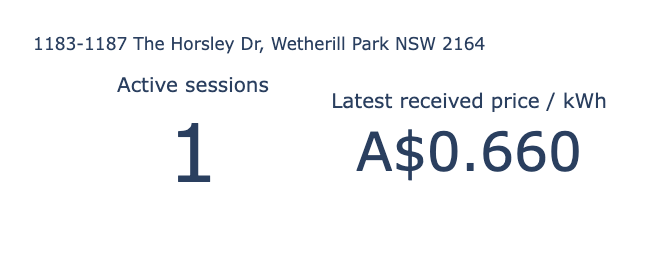

### history

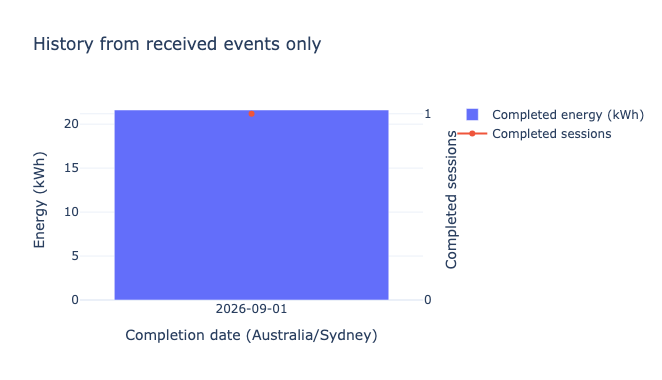

### live_curve

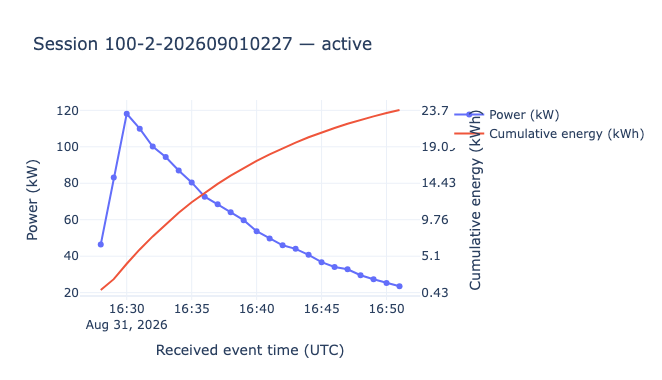

In [5]:
EV_ID = int(active.iloc[0].ev_id) if not active.empty else int(station_df.iloc[0].ev_id)
data = snapshot(db)
selected_station = next(s for s in data['stations'] if s['ev_id']==EV_ID)
selected_history = [r for r in data['daily_usage'] if r['ev_id']==EV_ID]
selected_session = next((s for s in data['sessions'] if s['ev_id']==EV_ID and s['status']=='active'), None)

figures = {
    'current_state': current_state_figure(selected_station),
    'history': history_figure(selected_history),
}
if selected_session:
    figures['live_curve'] = live_curve_figure(selected_session)
print('Selected station:',EV_ID,selected_station['display_name'])
for name, figure in figures.items():
    display(Markdown(f'### {name}'))
    figure.show()


## 6. Export the frontend handoff

Export an atomic JSON snapshot, DDL, and Plotly figures. The frontend can read the snapshot without opening the writer's DuckDB file. This notebook produces a saved snapshot; `subscriber.py listen` provides periodic updates during ingestion.

In [6]:
publish_snapshot(db, RUN/'dashboard.json')
shutil.copy2(ROOT/'sql/analytics.sql', RUN/'member3_schema.sql')
for name, figure in figures.items():
    figure.write_json(RUN/f'{name}.plotly.json')
    figure.write_html(RUN/f'{name}.html',include_plotlyjs=True)

exported = json.loads((RUN/'dashboard.json').read_text())
print('Snapshot fields:',list(exported))
print('Snapshot stations:',len(exported['stations']))
display(pd.DataFrame([{'file':p.name,'size_KB':round(p.stat().st_size/1024,1)}
                      for p in sorted(RUN.iterdir()) if p.suffix in ('.json','.sql','.html')]))


Snapshot fields: ['schema_version', 'published_at', 'coverage', 'stations', 'sessions', 'daily_usage']
Snapshot stations: 433


,file,size_KB
0,current_state.html,4710.6
1,current_state.plotly.json,6.8
2,dashboard.json,335.8
3,history.html,4710.8
4,history.plotly.json,7.0
5,live_curve.html,4712.3
6,live_curve.plotly.json,8.6
7,member3_schema.sql,6.6


## 7. Verify and save

Compare the original Assignment 1 and Member 2 tables row by row, then cross-check derived metrics against received events and the exported snapshot.

In [7]:
source_path = str(SOURCE_DB).replace("'","''")
db.execute(f"ATTACH '{source_path}' AS original (READ_ONLY)")
original_tables = db.execute("SELECT table_schema,table_name FROM information_schema.tables WHERE table_catalog='original' AND table_type='BASE TABLE' AND table_name NOT IN ('meter_reading','charging_session','current_price')").fetchall()
differences = []
for schema, table in original_tables:
    name = '"'+schema.replace('"','""')+'"."'+table.replace('"','""')+'"'
    count = db.execute(f'SELECT count(*) FROM ((SELECT * FROM original.{name} EXCEPT ALL SELECT * FROM {name}) UNION ALL (SELECT * FROM {name} EXCEPT ALL SELECT * FROM original.{name}))').fetchone()[0]
    differences.append(count)

counts = dict(db.execute('SELECT event_type,count(*) FROM core.mqtt_event GROUP BY event_type').fetchall())
expected_energy = db.execute("SELECT sum(CAST(payload->>'energy_kwh' AS DOUBLE)) FROM core.mqtt_event WHERE event_type='session_end'").fetchone()[0]
checks = {
    'a1_and_member2_tables_unchanged': all(n==0 for n in differences),
    'meter_count_matches_inbox': db.execute('SELECT count(*) FROM core.meter_reading').fetchone()[0]==counts.get('meter',0),
    'all_433_dc_stations_retained': len(station_df)==433,
    'completed_count_matches_end_events': totals['completed_sessions']==counts.get('session_end',0),
    'active_count_matches_window_lifecycle': len(active)==counts.get('session_start',0)-counts.get('session_end',0),
    'completed_energy_matches_end_events': abs(totals['completed_energy_kwh']-expected_energy)<0.00001,
    'snapshot_event_count_matches_database': exported['coverage']['received_events']==sum(counts.values()),
}
display(pd.DataFrame([{'check':k,'passed':bool(v)} for k,v in checks.items()]))
assert all(checks.values())
result = {'passed':True,'checks':checks,'events':sum(counts.values()),
          'active_sessions':len(active),**totals}
(RUN/'verification.json').write_text(json.dumps(result,ensure_ascii=False,indent=2),encoding='utf-8')
db.execute('DETACH original')
db.close()
print('All checks passed. Database saved:', DB_PATH.relative_to(ROOT))


,check,passed
0,a1_and_member2_tables_unchanged,True
1,meter_count_matches_inbox,True
2,all_433_dc_stations_retained,True
3,completed_count_matches_end_events,True
4,active_count_matches_window_lifecycle,True
5,completed_energy_matches_end_events,True
6,snapshot_event_count_matches_database,True


All checks passed. Database saved: artifacts/runs/20261027_022354_765488/assignment2_member3.duckdb


The database connection is closed after verification. To issue further queries, reconnect with `db = duckdb.connect(str(DB_PATH))`. Each complete run writes an independent output directory.